# Exploração da base MAGIC Gamma Telescope
Fonte: UCI. Eventos simulados de um telescópio Cherenkov: gama (g) vs. hádron (h).


In [1]:
import io
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
## Download
# Os dados não ficam no git, então o notebook baixa o arquivo da UCI na primeira vez que roda.
# Se ele já estiver na pasta dados/, o download é pulado.
URL = "https://archive.ics.uci.edu/static/public/159/magic+gamma+telescope.zip"
pasta = Path("dados")
arquivo = pasta / "magic04.data"

if not arquivo.exists():
    pasta.mkdir(exist_ok=True)
    with urllib.request.urlopen(URL) as resposta:
        zipfile.ZipFile(io.BytesIO(resposta.read())).extractall(pasta)

print(arquivo, f"{arquivo.stat().st_size / 1e6:.1f} MB")

dados\magic04.data 1.5 MB


In [3]:
#A base de dados não tem cabeçalho, por isso aqui tive que criar um de acordo com as informações do magic04.names
colunas = ["fLength", "fWidth", "fSize", "fConc", "fConc1", "fAsym", "fM3Long", "fM3Trans", "fAlpha", "fDist", "class"]

In [4]:
#Carregamento de dados
df = pd.read_csv("dados/magic04.data", header=None, names=colunas)

In [5]:
## Estrutura
#Verificação dos dados
df.shape # shape: mostra o tamanho da tabela no formato (linhas, colunas)

(19020, 11)

In [6]:
df.head() # head: mostra as 5 primeiras linhas para conferir como os dados estão

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [7]:
df.info() # info: resumo das colunas (nome, tipo de dado e quantos valores não estão vazios)

<class 'pandas.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   fLength   19020 non-null  float64
 1   fWidth    19020 non-null  float64
 2   fSize     19020 non-null  float64
 3   fConc     19020 non-null  float64
 4   fConc1    19020 non-null  float64
 5   fAsym     19020 non-null  float64
 6   fM3Long   19020 non-null  float64
 7   fM3Trans  19020 non-null  float64
 8   fAlpha    19020 non-null  float64
 9   fDist     19020 non-null  float64
 10  class     19020 non-null  str    
dtypes: float64(10), str(1)
memory usage: 1.6 MB


In [8]:
## Qualidade dos dados
df.isna().sum() # Conta quantos valores vazios (NaN) existem em cada coluna
                # isna() marca True nas células vazias; sum() soma os True de cada coluna

fLength     0
fWidth      0
fSize       0
fConc       0
fConc1      0
fAsym       0
fM3Long     0
fM3Trans    0
fAlpha      0
fDist       0
class       0
dtype: int64

In [9]:
df.duplicated().sum() # Quantas linhas duplicadas existem na tabela

np.int64(115)

In [10]:
## Estatísticas
df.describe() # (contagem, média, desvio padrão, mínimo, quartis e máximo)

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist
count,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000
mean,53.250154,22.180966,2.825017,0.380327,0.214657,-4.331745,10.545545,0.249726,27.645707,193.818026
std,42.364855,18.346056,0.472599,0.182813,0.110511,59.206062,51.000118,20.827439,26.103621,74.731787
min,4.283500,0.000000,1.941300,0.013100,0.000300,-457.916100,-331.780000,-205.894700,0.000000,1.282600
25%,24.336000,11.863800,2.477100,0.235800,0.128475,-20.586550,-12.842775,-10.849375,5.547925,142.492250
50%,37.147700,17.139900,2.739600,0.354150,0.196500,4.013050,15.314100,0.666200,17.679500,191.851450
75%,70.122175,24.739475,3.101600,0.503700,0.285225,24.063700,35.837800,10.946425,45.883550,240.563825
max,334.177000,256.382000,5.323300,0.893000,0.675200,575.240700,238.321000,179.851000,90.000000,495.561000


In [11]:
df["class"].value_counts() # Conta quantos registros existem de cada classe na coluna "class"

class
g    12332
h     6688
Name: count, dtype: int64

In [12]:
df["class"].value_counts(normalize=True) # Mostra a proporção de cada classe na coluna

class
g    0.64837
h    0.35163
Name: proportion, dtype: float64

## Gráficos

In [13]:
# Cores: azul para gama (g), laranja para hádron (h)
CORES = {"g": "#2a78d6", "h": "#eb6834"}
NOMES = {"g": "Gama (g)", "h": "Hádron (h)"}

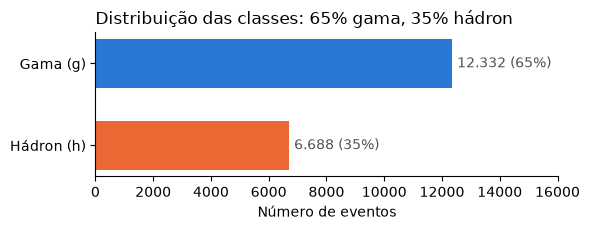

In [14]:
# Gráfico 1: quantos eventos há em cada classe
contagem = df["class"].value_counts()

fig, ax = plt.subplots(figsize=(6, 2.4))
barras = ax.barh([NOMES[c] for c in contagem.index], contagem.values,
                 color=[CORES[c] for c in contagem.index], height=0.6)
ax.bar_label(barras, labels=[f"{n:,} ({n / len(df):.0%})".replace(",", ".") for n in contagem.values],
             padding=4, color="#52514e")
ax.invert_yaxis()                      # gama em cima
ax.set_xlim(0, contagem.max() * 1.3)   # espaço para o rótulo
ax.set_xlabel("Número de eventos")
ax.set_title("Distribuição das classes: 65% gama, 35% hádron", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

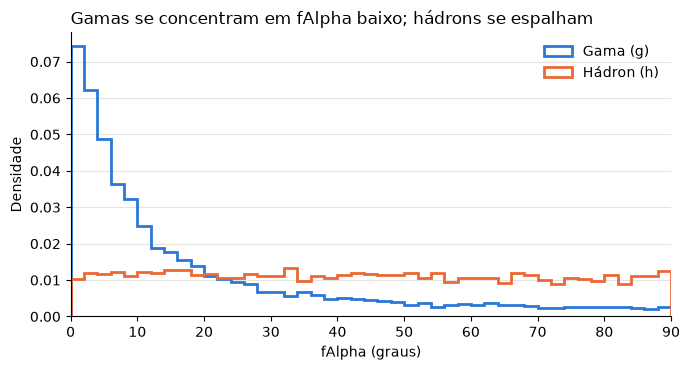

In [15]:
# Gráfico 2: distribuição de fAlpha por classe
# fAlpha é o ângulo entre o eixo maior da elipse e a direção da fonte.
# Chuveiros de raios gama apontam para a fonte, então devem ter fAlpha perto de 0.
fig, ax = plt.subplots(figsize=(7, 3.8))
for classe in ["g", "h"]:
    valores = df.loc[df["class"] == classe, "fAlpha"]
    ax.hist(valores, bins=45, range=(0, 90), density=True, histtype="step",
            linewidth=2, color=CORES[classe], label=NOMES[classe])

ax.set_xlabel("fAlpha (graus)")
ax.set_ylabel("Densidade")
ax.set_xlim(0, 90)
ax.set_title("Gamas se concentram em fAlpha baixo; hádrons se espalham", loc="left")
ax.legend(frameon=False)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [16]:
# Confere a diferença em números: mediana de fAlpha por classe
df.groupby("class")["fAlpha"].median()

class
g     9.70815
h    43.38290
Name: fAlpha, dtype: float64

## Resumo

### O que é a base
O telescópio MAGIC, nas Ilhas Canárias, observa raios gama (o sinal que interessa aos astrônomos) e raios cósmicos, chamados hádrons (o ruído). Quando eles batem no topo da atmosfera, provocam uma reação em cadeia: uma partícula vira várias. Isso é chamado de chuveiro de partículas. Esse chuveiro solta um clarão azulado (luz Cherenkov), e o telescópio fotografa esse clarão.

### Estrutura
Na câmera, o clarão aparece como uma mancha em forma de elipse. A base tem 19.020 dessas fotos, todas simuladas em computador. Em vez da imagem, cada linha guarda 10 números que descrevem a mancha (comprimento, largura, brilho, simetria, direção, distância do centro etc.) e uma 11ª coluna com a resposta certa: gama (`g`) ou hádron (`h`).

### Qualidade
Não falta nenhum valor. Há 115 linhas repetidas, com os 11 valores exatamente iguais, o que pode ser coincidência ou erro de geração. São poucas (0,6%), mas vale decidir se ficam ou saem antes de treinar um modelo.

### Classes desequilibradas
Cerca de 2 em cada 3 eventos são gama. Um modelo preguiçoso que respondesse "gama" para tudo já acertaria 65% das vezes sem ter aprendido nada. Por isso a acurácia sozinha não basta: é preciso ver também quantos hádrons passam como se fossem gama. No céu de verdade, os hádrons são muito mais numerosos; a proporção de 65/35 vale só para esta simulação.

### A pista mais forte: fAlpha
O fAlpha mede para onde a mancha aponta em relação ao alvo do telescópio. Raios gama são luz, viajam em linha reta e chegam da fonte observada, então a mancha aponta para o alvo (mediana de 9,7°). Hádrons são desviados pelos campos magnéticos da galáxia e chegam de qualquer direção (mediana de 43,4°). Por isso esse ângulo é a melhor pista para separar sinal de ruído.

### Normalizar
As medidas estão em escalas muito diferentes: algumas vão de 0 a 1, outras chegam a 500. Sem ajuste, um modelo pode dar mais peso aos números grandes só por serem grandes. Normalizar coloca todas na mesma escala, para que cada medida conte de forma justa.
